# EDA: performance outliers

| Run | Model | Split |
|-----|-------|-------|
| `MViTv2_S_16x4_e_5mzfq88e_chained_s42` (thesis job 4's final model) | MViTv2_S_16x4_e | asl2000 |

Before 25 Oct 2026 the thesis used `MViTv2_S` `exp000` on `asl2000_cutoff_9_1_indexed`; its
figures are kept under that run's stub.

Visual inspection of the overachieving/underachieving glosses identified in
[correlation_f1.ipynb](./correlation_f1.ipynb)'s `<stub>performance_outliers.json`:
overachievers are low-signer-count glosses the model still gets right;
underachievers are high-signer-count glosses it still gets wrong. For each
underachiever this also looks at what the model predicts instead, reusing
the same stashed per-instance predictions `correlation_f1.ipynb` produced.


Also see the follow up notebook: [all_misspredictions](./all_misspredictions.ipynb).


In [1]:
from collections import Counter

import pandas as pd
from IPython.display import display

from src.configs import get_class_list
from src.results import (
    format_exp_label,
    get_asset_path,
    get_out_stub,
    get_stash_path,
    load_json,
)
from src.stats import get_all_sets
from src.visualise2 import FrameFetcher, plot_frame_grid, save_fig, set_thesis_style

## Setup

In [2]:
from src.run_types import AVAIL_SETS, AVAIL_SPLITS

set_thesis_style()


split_name : AVAIL_SPLITS = 'asl2000' # exp000: 'asl2000_cutoff_9_1_indexed'
set_name : AVAIL_SETS = 'test'
model_name = 'MViTv2_S_e' # final model (job 78); job 4: 'MViTv2_S_16x4_e'; exp000: 'MViTv2_S'; the S3D comparison: 'S3D'
exp_no = 'MViTv2_S_e_woitlmw6_s42' # job 4: 'MViTv2_S_16x4_e_5mzfq88e_chained_s42'; exp000: '000'; the S3D comparison: 'S3D_cs9lwmiy_s42'
project_name = 'error_analysis'
num_underachievers_shown = 4 # change to inspect more/fewer
target_length = 16
grid_cell_size = (2.0, 2.0) # smaller than plot_frame_grid's default -- many grids shown below

stub = get_out_stub(split_name, model_name, format_exp_label(exp_no))

classes = get_class_list()
class_to_idx = {gloss: idx for idx, gloss in enumerate(classes)}
all_sets = get_all_sets(split_name)

## Load performance outliers and stashed predictions

In [3]:
outliers = load_json(get_stash_path(stub, base_name='performance_outliers'))

overachievers_df = pd.DataFrame(outliers['overachievers'])
underachievers_df = pd.DataFrame(outliers['underachievers'])

print(f'{len(overachievers_df)} overachievers, {len(underachievers_df)} underachievers')
display(overachievers_df)
underachievers_df.head(num_underachievers_shown)

5 overachievers, 2 underachievers


,Gloss,Instances,Signers,F1_Score
0,come here,5,3,1.0
1,wash face,5,3,1.0
2,obsess,5,3,1.0
3,overcome,5,3,1.0
4,post,5,3,1.0


,Gloss,Instances,Signers,F1_Score
0,before,18,13,0.0
1,eat,14,13,0.0


In [4]:
all_results = load_json(get_stash_path(stub))

all_targets = all_results['all_targets']
all_preds = all_results['all_preds']
print(f'Loaded {len(all_targets)} test-set predictions from {get_stash_path(stub).name}')

Loaded 2879 test-set predictions from asl2000_MViTv2_S_e_MViTv2_S_e_woitlmw6_s42_results.json


## Overachieving glosses

Low signer count, but the model still gets these right.

"come here" -- F1=1.00, 3 signers, 5 instances


Saved: overachiever_come_here_asl2000_MViTv2_S_e_MViTv2_S_e_woitlmw6_s42_.pdf
"wash face" -- F1=1.00, 3 signers, 5 instances


Saved: overachiever_wash_face_asl2000_MViTv2_S_e_MViTv2_S_e_woitlmw6_s42_.pdf
"obsess" -- F1=1.00, 3 signers, 5 instances


Saved: overachiever_obsess_asl2000_MViTv2_S_e_MViTv2_S_e_woitlmw6_s42_.pdf
"overcome" -- F1=1.00, 3 signers, 5 instances


Saved: overachiever_overcome_asl2000_MViTv2_S_e_MViTv2_S_e_woitlmw6_s42_.pdf
"post" -- F1=1.00, 3 signers, 5 instances


Saved: overachiever_post_asl2000_MViTv2_S_e_MViTv2_S_e_woitlmw6_s42_.pdf


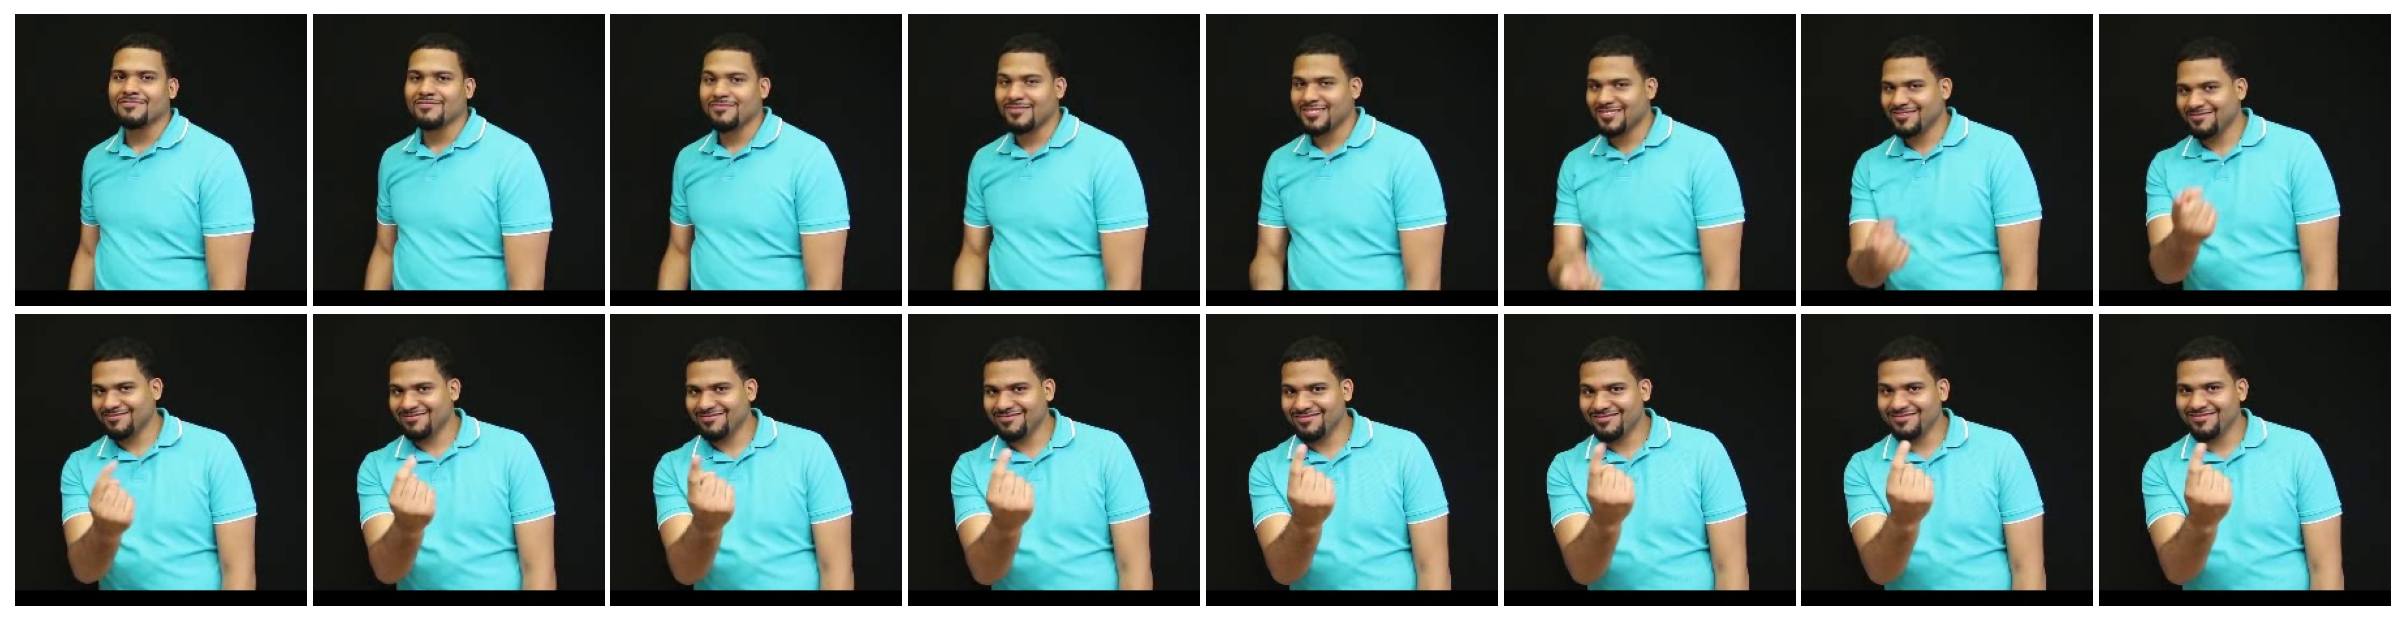

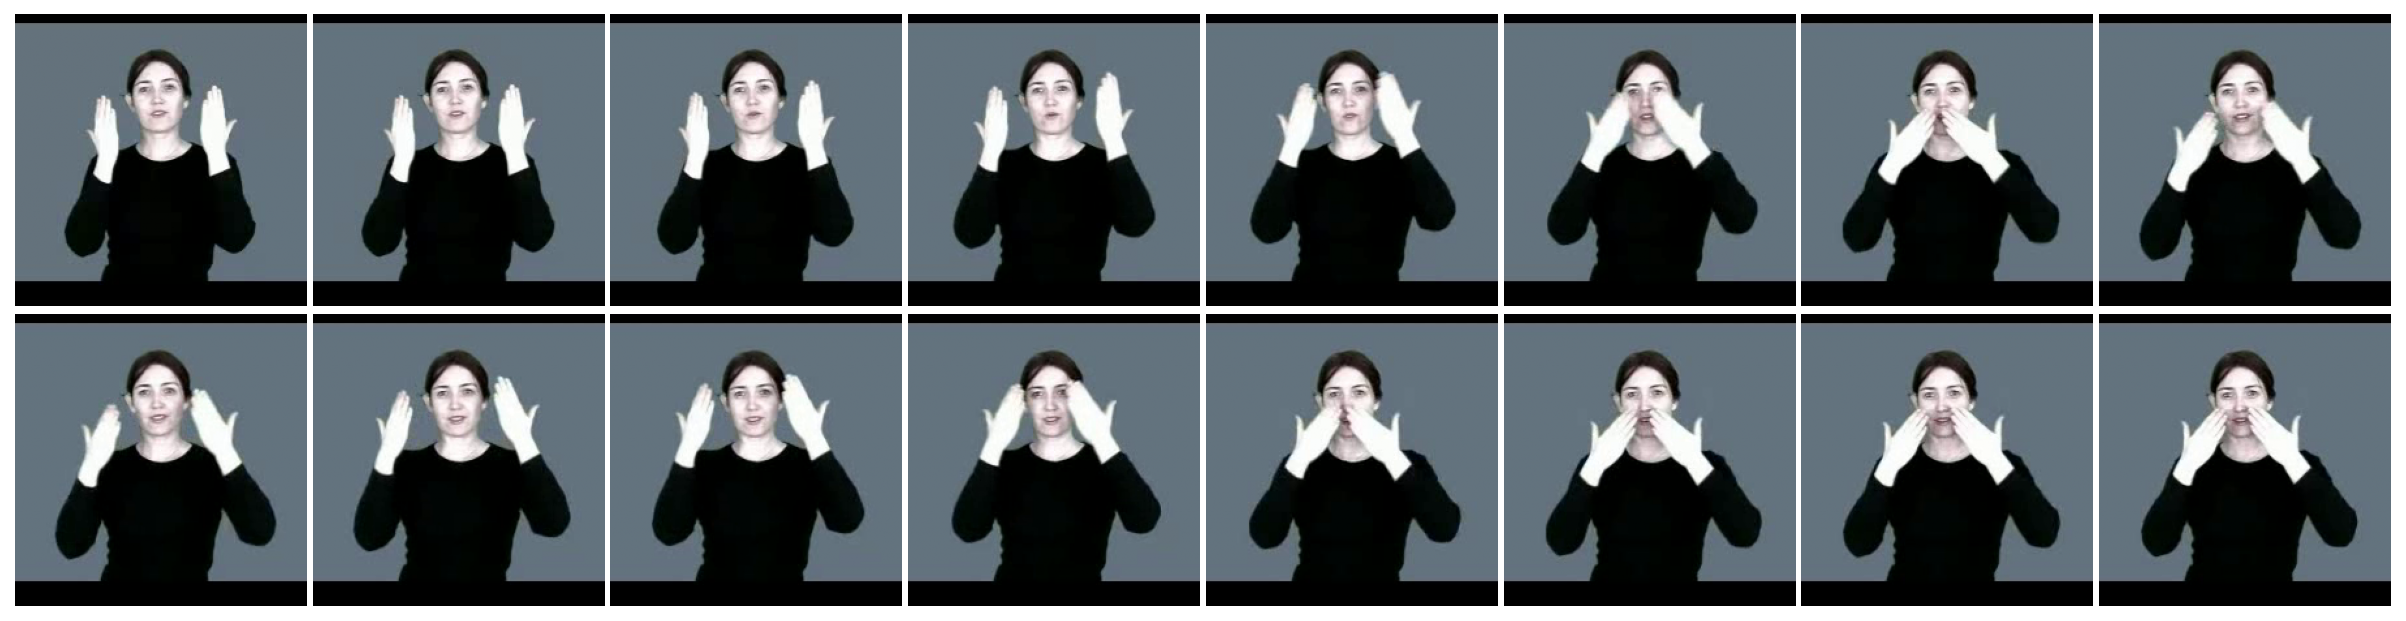

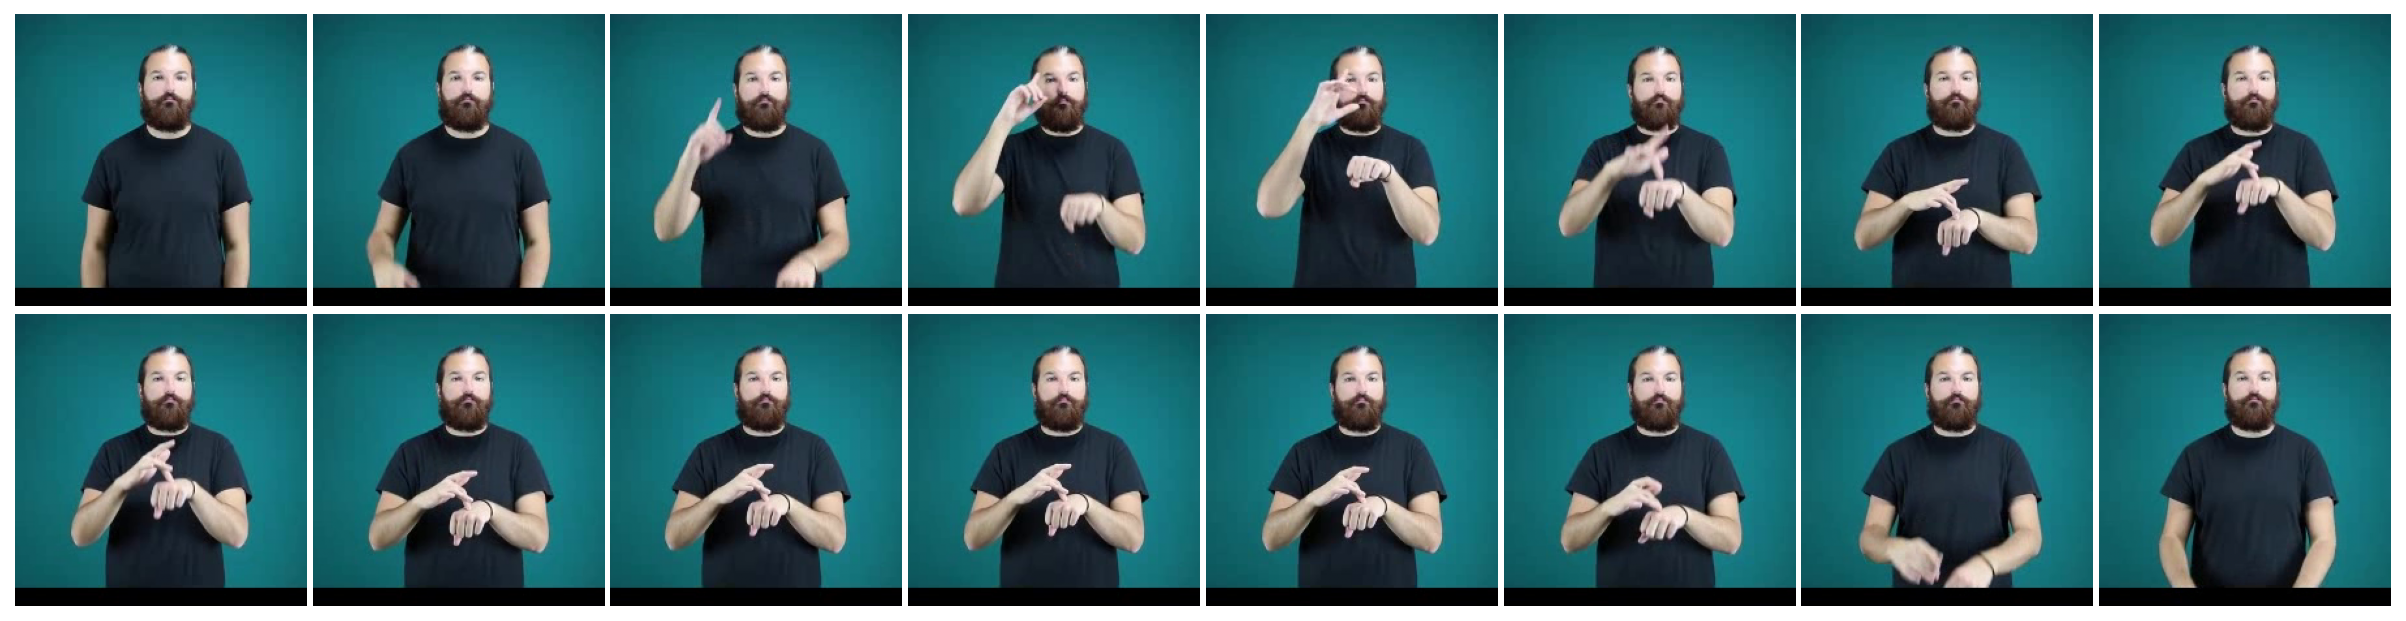

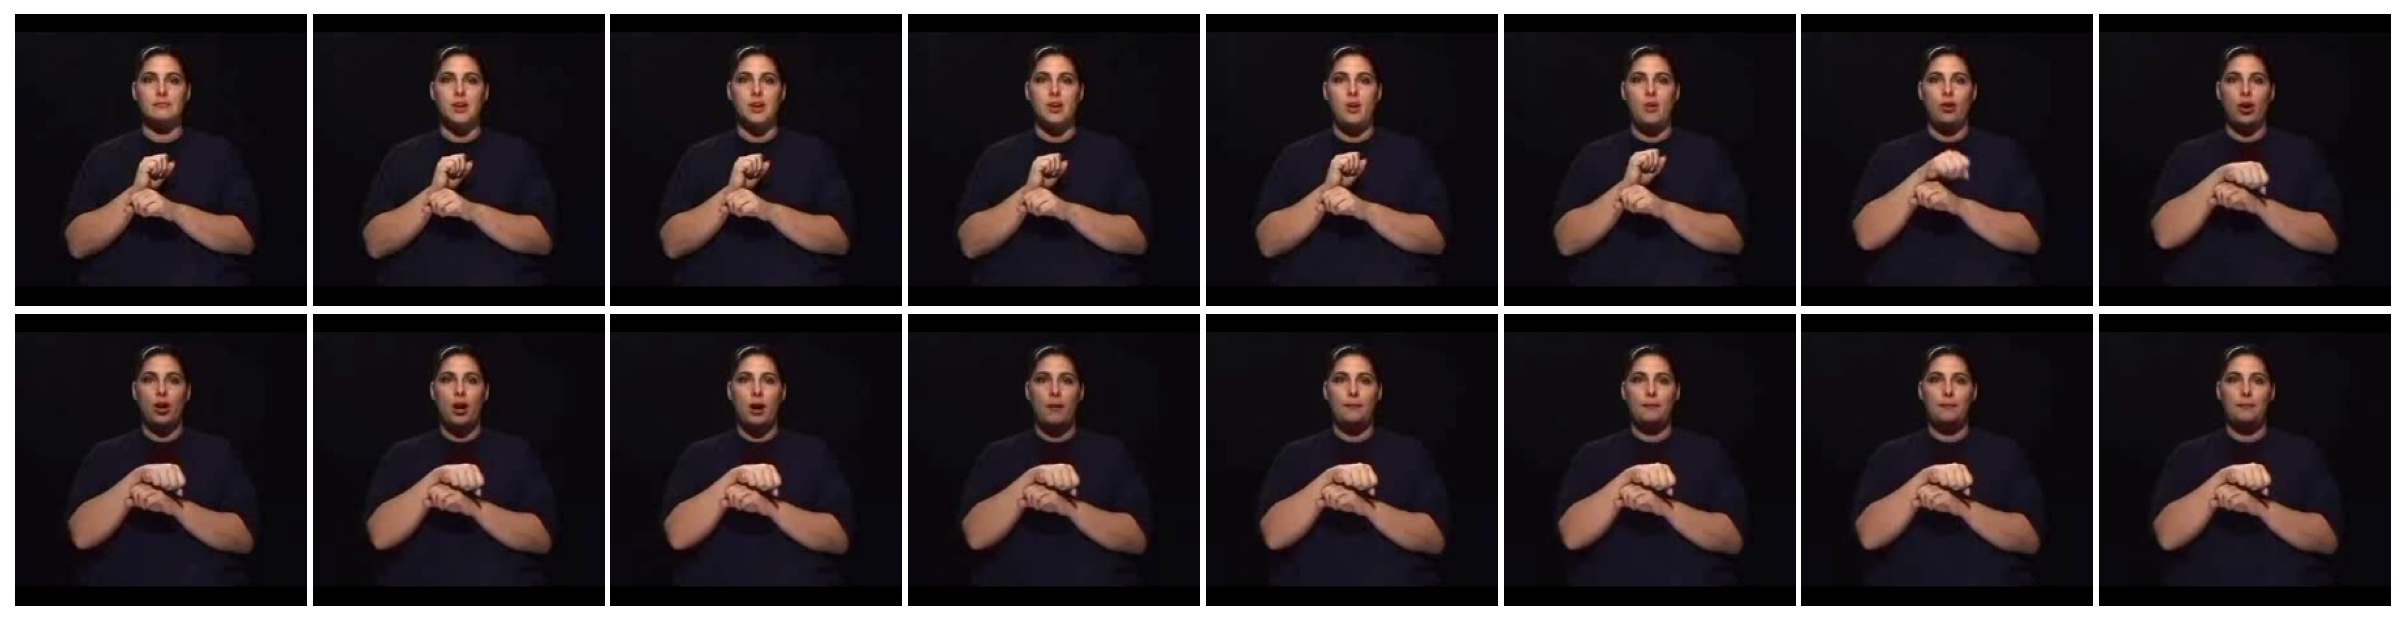

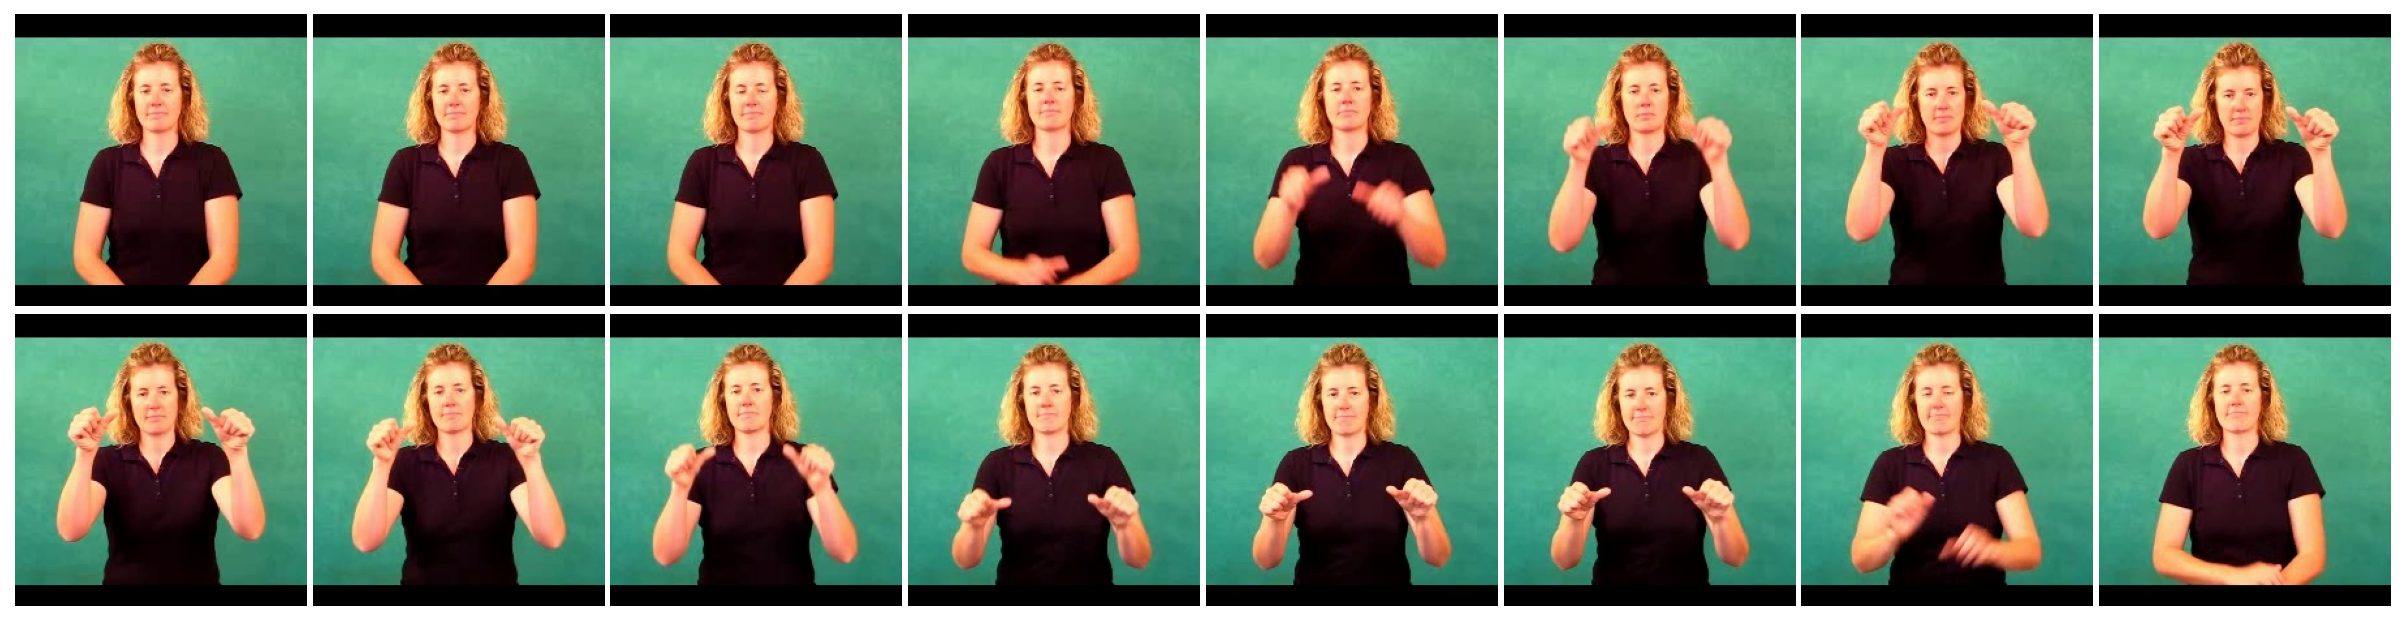

In [5]:
for _, row in overachievers_df.iterrows():
    gloss = row['Gloss']
    print(f'"{gloss}" -- F1={row["F1_Score"]:.2f}, {row["Signers"]} signers, {row["Instances"]} instances')
    frames = FrameFetcher(
        cls_idx=class_to_idx[gloss],
        all_sets=all_sets,
        set_name=set_name,
        split_name=split_name,
        target_length=target_length,
    )()
    fig, _ = plot_frame_grid(frames, num=target_length, size=grid_cell_size)
    path = save_fig(fig, get_asset_path(f'overachiever_{gloss}', stub, project_name))
    print(f'Saved: {path.name}')

## Underachieving glosses

High signer count, but the model still gets these wrong -- and what it
predicts instead (the most common misprediction across the test set).
Every instance's prediction (not just the most common), with top-k confidences, is in
[all_misspredictions.ipynb](./all_misspredictions.ipynb).

"before" -- F1=0.00, 13 signers, 18 instances


Most common misprediction: "former" (1/4 wrong instances)


Saved true/misprediction pair: underachiever_true_before_asl2000_MViTv2_S_e_MViTv2_S_e_woitlmw6_s42_.pdf, underachiever_pred_before_as_former_asl2000_MViTv2_S_e_MViTv2_S_e_woitlmw6_s42_.pdf
"eat" -- F1=0.00, 13 signers, 14 instances


Most common misprediction: "jewish" (1/2 wrong instances)


Saved true/misprediction pair: underachiever_true_eat_asl2000_MViTv2_S_e_MViTv2_S_e_woitlmw6_s42_.pdf, underachiever_pred_eat_as_jewish_asl2000_MViTv2_S_e_MViTv2_S_e_woitlmw6_s42_.pdf


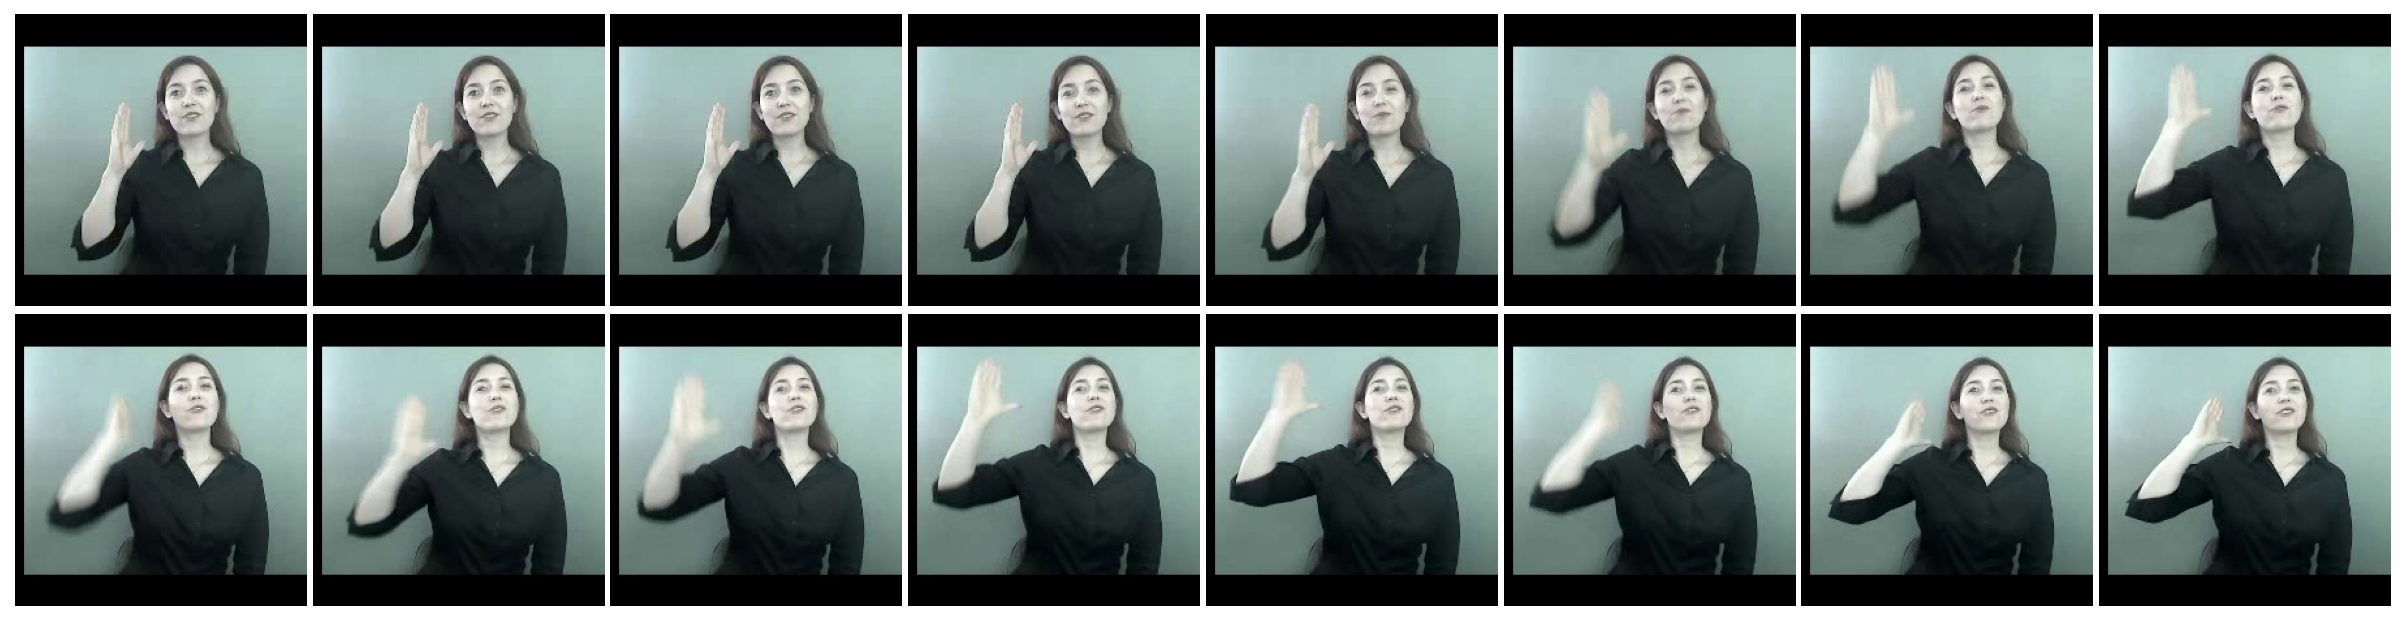

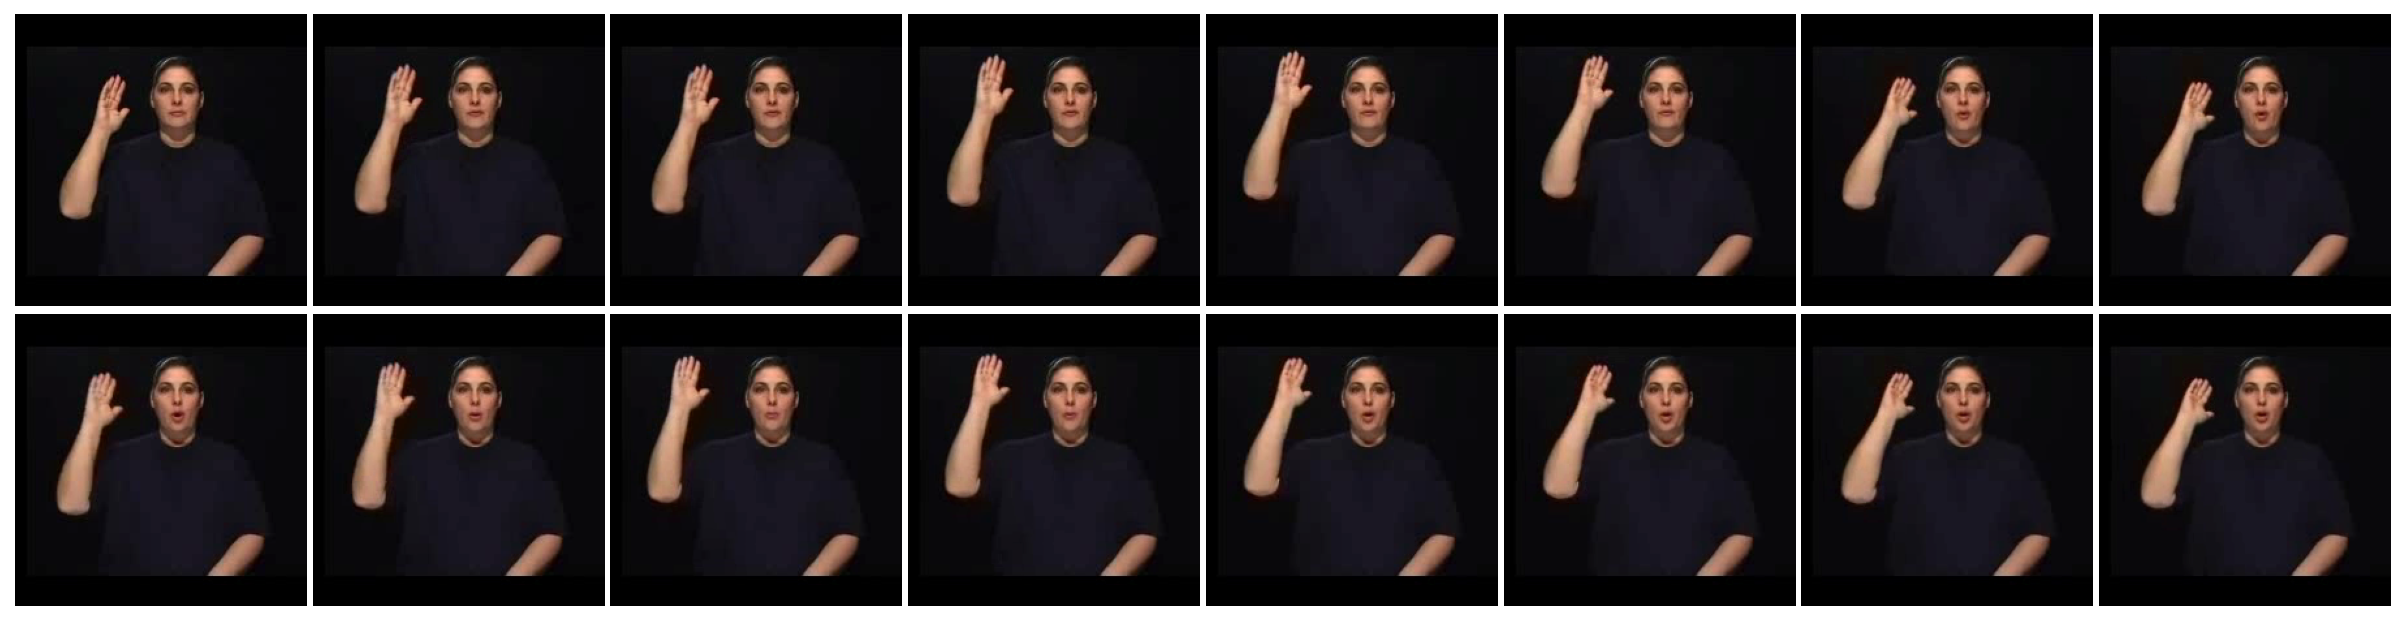

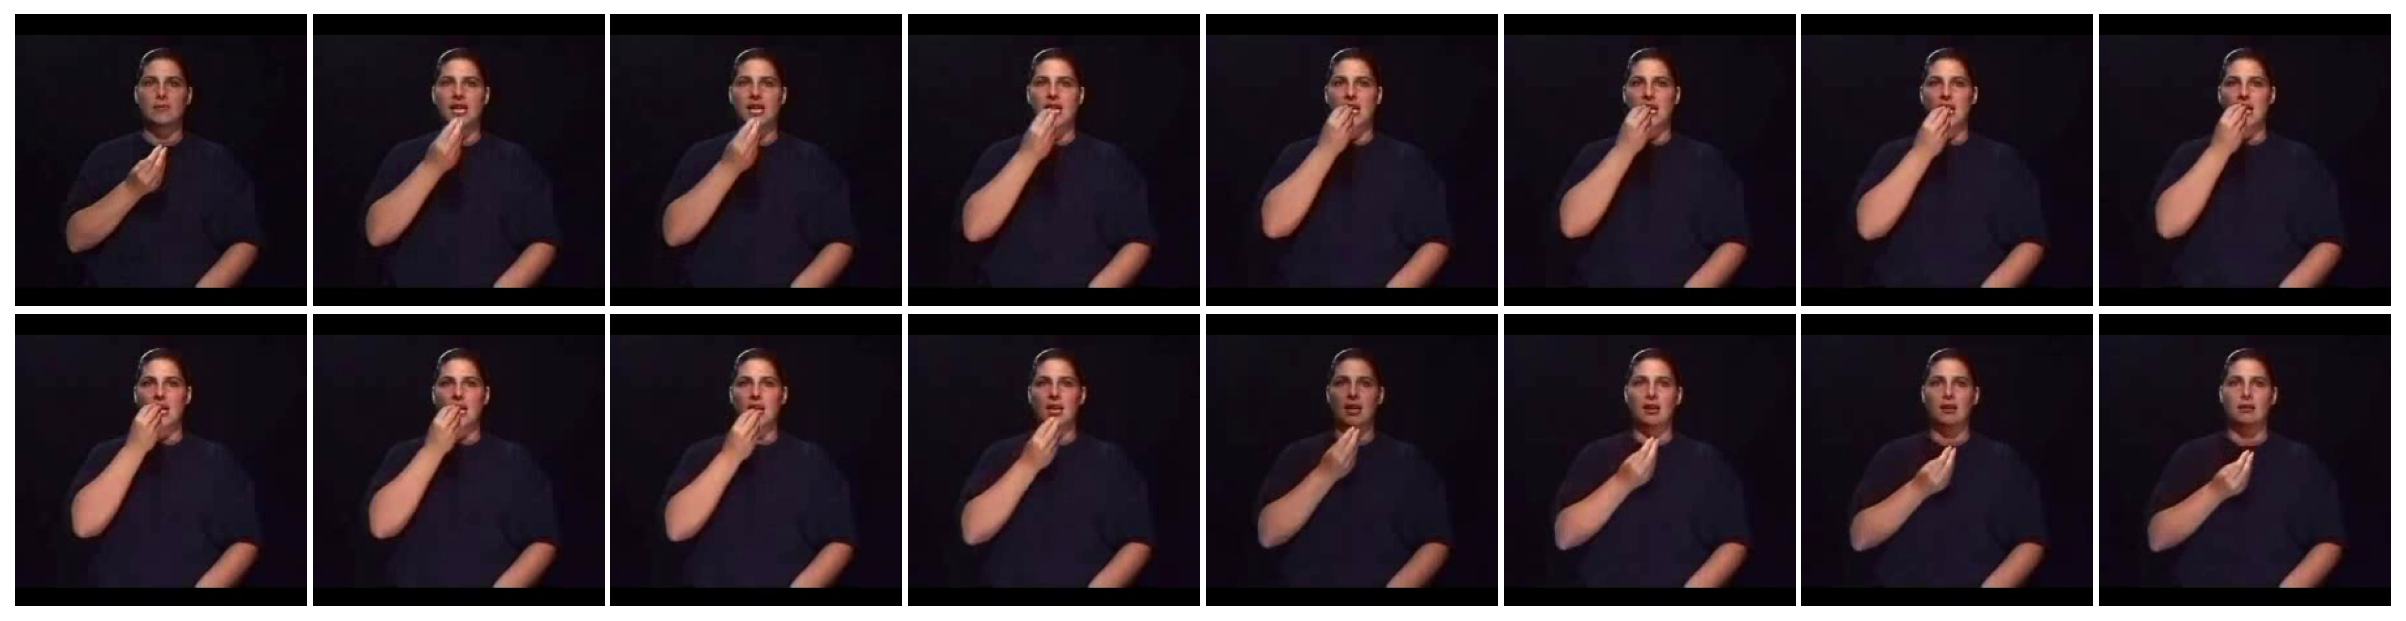

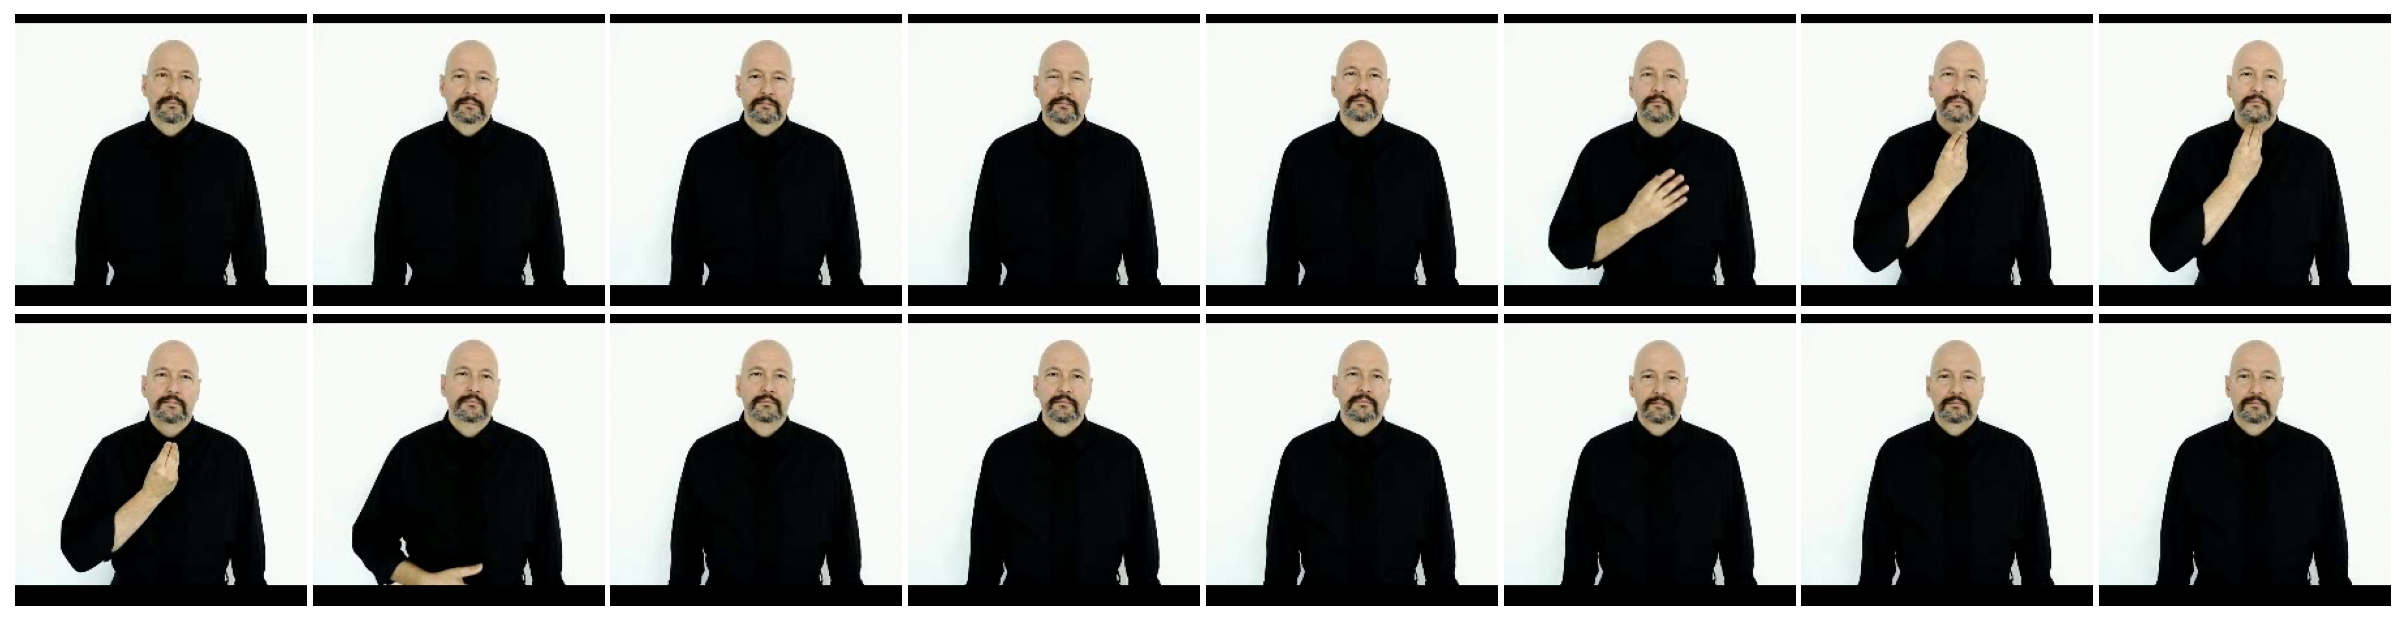

In [6]:
for _, row in underachievers_df.head(num_underachievers_shown).iterrows():
    gloss = row['Gloss']
    cls_idx = class_to_idx[gloss]
    print(f'"{gloss}" -- F1={row["F1_Score"]:.2f}, {row["Signers"]} signers, {row["Instances"]} instances')
    frames = FrameFetcher(
        cls_idx=cls_idx,
        all_sets=all_sets,
        set_name=set_name,
        split_name=split_name,
        target_length=target_length,
    )()
    true_fig, _ = plot_frame_grid(frames, num=target_length, size=grid_cell_size)
    true_path = save_fig(true_fig, get_asset_path(f'underachiever_true_{gloss}', stub, project_name))

    wrong_preds = [p for t, p in zip(all_targets, all_preds) if t == cls_idx and p != cls_idx]
    if not wrong_preds:
        print('No misclassified instances found for this gloss.')
        continue

    predicted_idx, count = Counter(wrong_preds).most_common(1)[0]
    predicted_gloss = classes[predicted_idx]
    print(f'Most common misprediction: "{predicted_gloss}" ({count}/{len(wrong_preds)} wrong instances)')
    pred_frames = FrameFetcher(
        cls_idx=predicted_idx,
        all_sets=all_sets,
        set_name=set_name,
        split_name=split_name,
        target_length=target_length,
    )()
    pred_fig, _ = plot_frame_grid(pred_frames, num=target_length, size=grid_cell_size)
    pred_path = save_fig(
        pred_fig, get_asset_path(f'underachiever_pred_{gloss}_as_{predicted_gloss}', stub, project_name)
    )
    print(f'Saved true/misprediction pair: {true_path.name}, {pred_path.name}')

# Continuing

See [all_misspredictions](./all_misspredictions.ipynb)